In [44]:
# ===== Imports =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
import os

# ===== Data Loading =====
data_path = "../data/clustering_dataset.csv"
df = pd.read_csv(data_path)

# Inspect dataset
print(df.head())

# ===== Feature Scaling =====
scaler = StandardScaler()
X = scaler.fit_transform(df.values)  # Scale features for distance-based clustering

         x        y
0  262.354   90.171
1   58.571  357.793
2  210.552  263.524
3  156.131  260.007
4  135.543  388.240


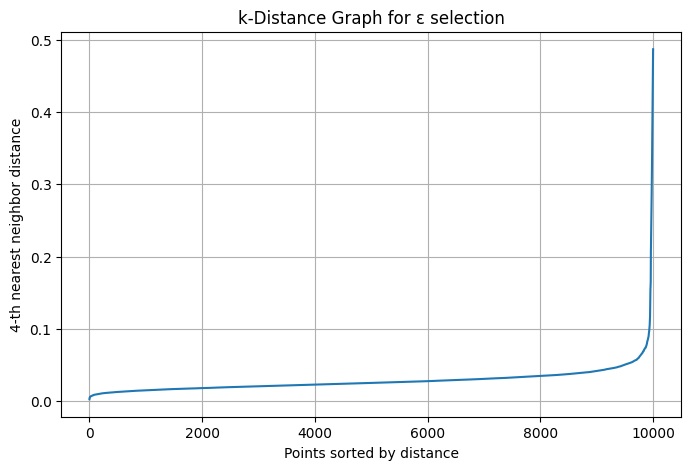

In [45]:
# ===== K-Distance Graph =====
min_pts = 4  # Common default: MinPts >= dimensions + 1

# Use NearestNeighbors to find distances to k-th neighbor
nbrs = NearestNeighbors(n_neighbors=min_pts).fit(X)
distances, indices = nbrs.kneighbors(X)

# k-distance = distance to min_pts-th neighbor
k_distances = np.sort(distances[:, -1])  # Sort to plot elbow

# Plot sorted k-distances
plt.figure(figsize=(8,5))
plt.plot(k_distances)
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_pts}-th nearest neighbor distance')
plt.title('k-Distance Graph for ε selection')
plt.grid(True)
plt.show()

In [46]:
class DBSCAN:
    """
    Scratch implementation of DBSCAN.
    Core logic:
    1. Classify points as Core, Border, Noise.
    2. Expand clusters from core points using BFS.
    """
    def __init__(self, eps=0.075, min_pts=4):
        self.eps = eps
        self.min_pts = min_pts

    def fit(self, X):
        self.X = X
        n_points = X.shape[0]
        self.labels_ = np.full(n_points, -1)  # -1 = Noise
        self.core_points_ = np.zeros(n_points, dtype=bool)
        self.visited_ = np.zeros(n_points, dtype=bool)
        cluster_id = 0

        # ===== Compute ε-neighbors for all points =====
        self.neighbors_ = []
        for i in range(n_points):
            # Vectorized distance computation
            dist = np.linalg.norm(X - X[i], axis=1)
            neighbors = np.where(dist <= self.eps)[0]
            self.neighbors_.append(neighbors)
            if len(neighbors) >= self.min_pts:
                self.core_points_[i] = True  # Mark as core

        # ===== Expand clusters =====
        for i in range(n_points):
            if self.visited_[i]:
                continue
            self.visited_[i] = True

            if not self.core_points_[i]:
                continue  # Noise or border, skip

            # Start new cluster
            cluster_id += 1
            self._expand_cluster(i, cluster_id)

        return self

    def _expand_cluster(self, idx, cluster_id):
        """
        Expand cluster using BFS approach
        """
        queue = [idx]

        while queue:
            point = queue.pop(0)
            if self.labels_[point] == -1:
                self.labels_[point] = cluster_id  # Assign cluster label

            if not self.core_points_[point]:
                continue  # Border points do not expand

            for neighbor in self.neighbors_[point]:
                if not self.visited_[neighbor]:
                    self.visited_[neighbor] = True
                    if self.core_points_[neighbor]:
                        queue.append(neighbor)
                if self.labels_[neighbor] == -1:
                    self.labels_[neighbor] = cluster_id

In [47]:
# Choose ε based on k-distance graph
eps = 0.075  # Example; pick the elbow point from previous plot
min_pts = 4

start_time = time.time()
dbscan = DBSCAN(eps=eps, min_pts=min_pts)
dbscan.fit(X)
run_time = time.time() - start_time

labels = dbscan.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise}")
print(f"Run time: {run_time:.2f} seconds")

Clusters found: 5
Noise points: 73
Run time: 2.97 seconds


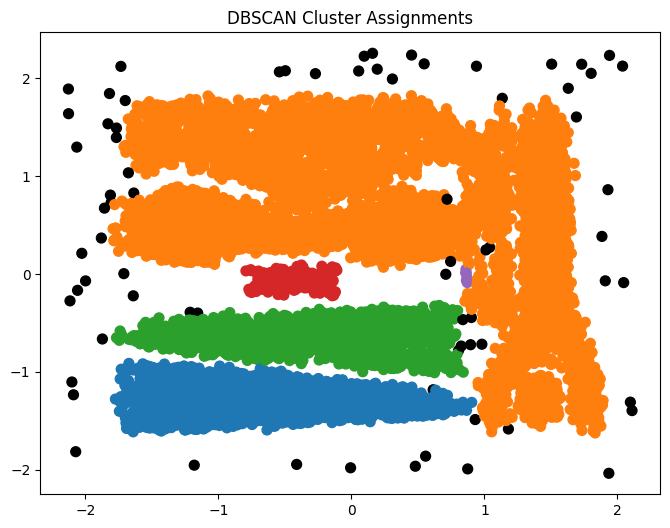

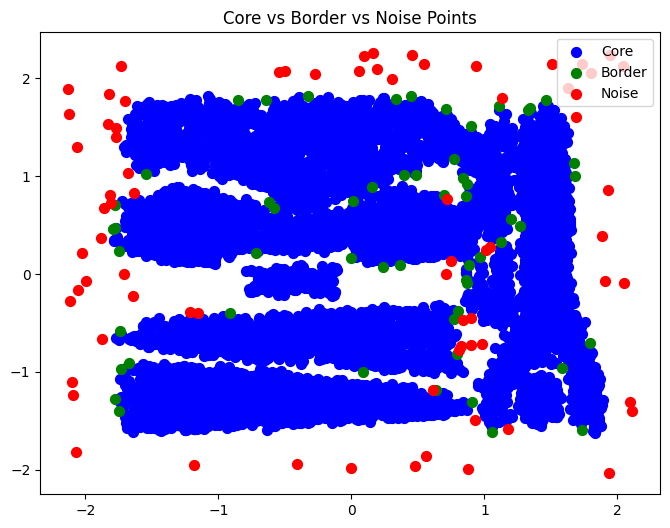

In [48]:
# ===== Assign colors for clusters =====
palette = sns.color_palette('tab10', n_clusters)
colors = [palette[label-1] if label != -1 else (0,0,0) for label in labels]  # Noise = black

plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=colors, s=50)
plt.title('DBSCAN Cluster Assignments')
plt.show()

# ===== Core vs Border vs Noise =====
core = dbscan.core_points_
border = ~core & (labels != -1)
noise = labels == -1

plt.figure(figsize=(8,6))
plt.scatter(X[core,0], X[core,1], c='blue', label='Core', s=50)
plt.scatter(X[border,0], X[border,1], c='green', label='Border', s=50)
plt.scatter(X[noise,0], X[noise,1], c='red', label='Noise', s=50)
plt.legend()
plt.title('Core vs Border vs Noise Points')
plt.show()

In [50]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import os

# Only calculate silhouette if >1 cluster
if n_clusters > 1:
    sil_score = silhouette_score(X, labels)
    db_score = davies_bouldin_score(X, labels)
    ch_score = calinski_harabasz_score(X, labels)
else:
    sil_score = db_score = ch_score = np.nan

# Save metrics to CSV
results_path = "../results.csv"

results_df = pd.DataFrame({
    "model": ["DBSCAN"],
    "n_clusters": [n_clusters],
    "epsilon": [eps],
    "min_pts": [min_pts],
    "inertia": [0],
    "silhouette": [sil_score],
    "davies_bouldin_score": [db_score],
    "calinski_harabasz_score": [ch_score],
    "n_noise": [n_noise],
    "run_time": [run_time]
})

# Append to results.csv
if os.path.exists(results_path):
    results_df.to_csv(results_path, index=False, mode='a', header=False)
else:
    results_df.to_csv(results_path, index=False)
    
print("Metrics saved to results.csv")

Metrics saved to results.csv
